In [ ]:
import numpy as np
import torch
import torch.nn as nn

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", dev)

# Simulate soil data (sand %, silt %, clay %, pH, organic matter) -> 4 soil classes
rng = np.random.default_rng(0)
X = torch.tensor(rng.uniform(0, 100, size=(200, 5)), dtype=torch.float32, device=dev)
y = torch.tensor(rng.integers(0, 4, size=(200,)), dtype=torch.long, device=dev)

Using device: cpu


In [ ]:
plain_net = nn.Sequential(
    nn.Linear(5, 32),
    nn.ReLU(),
    nn.Linear(32, 16),
    nn.ReLU(),
    nn.Linear(16, 4),
).to(dev)


adv_net = nn.Sequential(
    nn.Linear(5, 32),
    nn.BatchNorm1d(32),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(32, 16),
    nn.BatchNorm1d(16),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(16, 4),
).to(dev)

loss_fn = nn.CrossEntropyLoss()
opt_plain = torch.optim.Adam(plain_net.parameters(), lr=1e-3)
opt_adv = torch.optim.Adam(adv_net.parameters(), lr=1e-3)

Plain Eval Accuracy: 34.00% | BatchNorm+Dropout Eval Accuracy: 36.00%


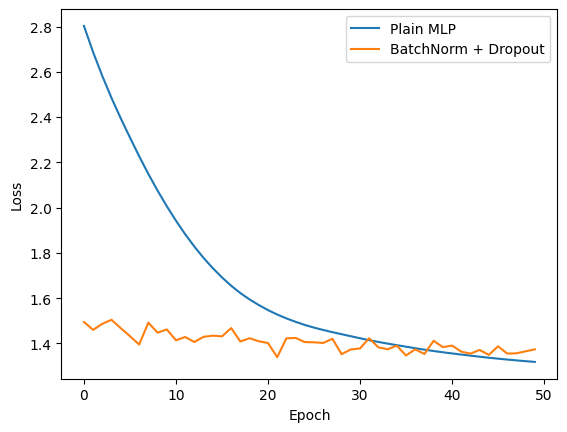

In [ ]:
import matplotlib.pyplot as plt

plain_losses, adv_losses = [], []

for epoch in range(1, 51):
    # Train plain model
    plain_net.train()
    opt_plain.zero_grad()
    l1 = loss_fn(plain_net(X), y)
    l1.backward()
    opt_plain.step()
    plain_losses.append(l1.item())

    # Train model with BatchNorm & Dropout
    adv_net.train()
    opt_adv.zero_grad()
    l2 = loss_fn(adv_net(X), y)
    l2.backward()
    opt_adv.step()
    adv_losses.append(l2.item())

# Switch to eval mode for checking accuracy
plain_net.eval()
adv_net.eval()
with torch.no_grad():
    acc_plain = (plain_net(X).argmax(dim=1) == y).float().mean().item()
    acc_adv = (adv_net(X).argmax(dim=1) == y).float().mean().item()

print(f"Plain Eval Accuracy: {acc_plain:.2%} | BatchNorm+Dropout Eval Accuracy: {acc_adv:.2%}")

plt.plot(plain_losses, label="Plain MLP")
plt.plot(adv_losses, label="BatchNorm + Dropout")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()